In [3]:
from pathlib import Path
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_ceic import load_cpi_series
from src.features.reconstruct_index import add_reconstructed_indices

In [4]:
print("Working directory:", Path.cwd())
print("Project root:", PROJECT_ROOT)
print("Python interpreter:", sys.executable)

Working directory: /Users/darrentay/Desktop/SMU MDSE/August 2026 Term/DS607/Project/china-inflation-forecasting/notebooks
Project root: /Users/darrentay/Desktop/SMU MDSE/August 2026 Term/DS607/Project/china-inflation-forecasting
Python interpreter: /Users/darrentay/Desktop/SMU MDSE/August 2026 Term/DS607/Project/china-inflation-forecasting/.venv/bin/python


In [5]:
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "china_cpi.csv"

cpi = load_cpi_series(DATA_PATH)

cpi.head()

,headline_yoy_published,headline_mom_published,core_yoy_published,core_mom_published
date,,,,
1985-01-01,5.5,NaN,NaN,NaN
1985-02-01,6.5,NaN,NaN,NaN
1985-03-01,7.0,NaN,NaN,NaN
1985-04-01,7.8,NaN,NaN,NaN
1985-05-01,9.9,NaN,NaN,NaN


In [9]:
cpi.info()
cpi.tail()
cpi.notna().sum()

<class 'pandas.DataFrame'>
DatetimeIndex: 500 entries, 1985-01-01 to 2026-08-01
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   headline_yoy_published  500 non-null    float64
 1   headline_mom_published  380 non-null    float64
 2   core_yoy_published      248 non-null    float64
 3   core_mom_published      248 non-null    float64
dtypes: float64(4)
memory usage: 19.5 KB


headline_yoy_published    500
headline_mom_published    380
core_yoy_published        248
core_mom_published        248
dtype: int64

In [10]:
cpi_reconstructed = add_reconstructed_indices(cpi)

cpi_reconstructed.tail()

,headline_yoy_published,headline_mom_published,core_yoy_published,core_mom_published,headline_index_reconstructed,core_index_reconstructed,headline_yoy_reconstructed,core_yoy_reconstructed,headline_yoy_discrepancy,core_yoy_discrepancy
date,,,,,,,,,,
2026-04-01,1.2,0.3,1.2,0.2,177.527703,124.787561,1.298736,1.200351,0.098736,0.000351
2026-05-01,1.2,-0.1,1.1,-0.1,177.350175,124.662774,1.400238,1.099150,0.200238,-0.000850
2026-06-01,1.0,-0.3,1.0,-0.1,176.818125,124.538111,1.197235,0.998051,0.197235,-0.001949
2026-07-01,0.5,-0.1,0.9,0.3,176.641307,124.911725,0.693264,0.897456,0.193264,-0.002544
2026-08-01,0.8,0.4,1.0,0.1,177.347872,125.036637,1.096037,0.998353,0.296037,-0.001647


In [11]:
cpi_reconstructed.columns.tolist()

['headline_yoy_published',
 'headline_mom_published',
 'core_yoy_published',
 'core_mom_published',
 'headline_index_reconstructed',
 'core_index_reconstructed',
 'headline_yoy_reconstructed',
 'core_yoy_reconstructed',
 'headline_yoy_discrepancy',
 'core_yoy_discrepancy']

In [12]:
discrepancy_columns = [
    "headline_yoy_discrepancy",
    "core_yoy_discrepancy",
]

cpi_reconstructed.loc["2006-01-01":, discrepancy_columns].describe()

,headline_yoy_discrepancy,core_yoy_discrepancy
count,248.000000,236.000000
mean,0.005544,-0.033146
std,0.131437,0.117175
min,-0.313920,-0.305097
25%,-0.091581,-0.100232
50%,0.002290,-0.001798
75%,0.093527,0.012397
max,0.592205,0.299598


In [13]:
display_columns = [
    "headline_yoy_published",
    "headline_yoy_reconstructed",
    "headline_yoy_discrepancy",
    "core_yoy_published",
    "core_yoy_reconstructed",
    "core_yoy_discrepancy",
]

cpi_reconstructed[display_columns].tail(12)

,headline_yoy_published,headline_yoy_reconstructed,headline_yoy_discrepancy,core_yoy_published,core_yoy_reconstructed,core_yoy_discrepancy
date,,,,,,
2025-09-01,-0.3,-0.505565,-0.205565,1.0,1.002296,0.002296
2025-10-01,0.2,-0.006596,-0.206596,1.2,1.204301,0.004301
2025-11-01,0.7,0.496389,-0.203611,1.2,1.204301,0.004301
2025-12-01,0.8,0.697382,-0.102618,1.2,1.204301,0.004301
2026-01-01,0.2,0.197395,-0.002605,0.8,1.002899,0.202899
2026-02-01,1.3,1.402173,0.102173,1.8,1.913747,0.113747
2026-03-01,1.0,1.096745,0.096745,1.1,1.200351,0.100351
2026-04-01,1.2,1.298736,0.098736,1.2,1.200351,0.000351
2026-05-01,1.2,1.400238,0.200238,1.1,1.099150,-0.000850


<Axes: title={'center': 'Mainland China Core CPI Inflation'}, ylabel='Year-on-year inflation (%)'>

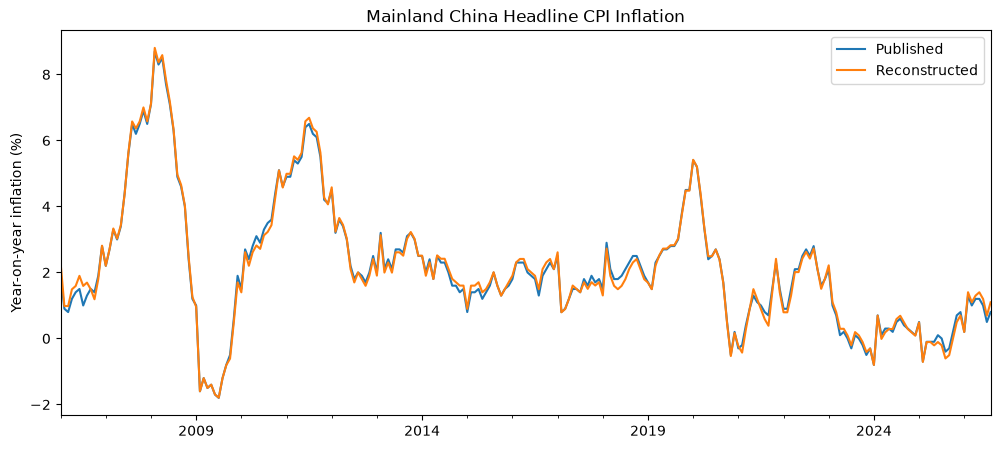

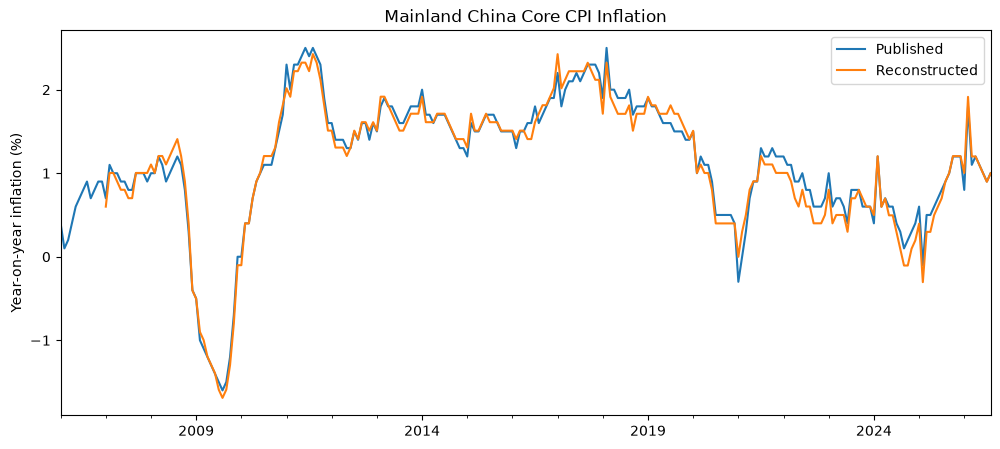

In [16]:
headline_plot = cpi_reconstructed.loc[
    "2006-01-01":,
    [
        "headline_yoy_published",
        "headline_yoy_reconstructed",
    ],
].rename(
    columns={
        "headline_yoy_published": "Published",
        "headline_yoy_reconstructed": "Reconstructed",
    }
)

headline_plot.plot(
    title="Mainland China Headline CPI Inflation",
    xlabel="",
    ylabel="Year-on-year inflation (%)",
    figsize=(12, 5),
)

core_plot = cpi_reconstructed.loc[
    "2006-01-01":,
    [
        "core_yoy_published",
        "core_yoy_reconstructed",
    ],
].rename(
    columns={
        "core_yoy_published": "Published",
        "core_yoy_reconstructed": "Reconstructed",
    }
)

core_plot.plot(
    title="Mainland China Core CPI Inflation",
    xlabel="",
    ylabel="Year-on-year inflation (%)",
    figsize=(12, 5),
)